### 1. Inicijalizacija okruženja i bezbedno povezivanje na bazu podataka

- **Konfiguracija okruženja i bezbednost:** Osetljivi parametri konekcije (IP adresa udaljenog servera, korisničko ime i lozinka) uspešno su izdvojeni u lokalni sistemski `.env` fajl. Time su ispunjeni standardi bezbednosti softverskog razvoja, a baza je zaštićena od javnog eksponiranja na GitHub repozitorijumu (kroz `.gitignore` mehanizam i prateći `.env.template` šablon).

- **Dinamičko učitavanje parametara:** Upotrebom biblioteka `python-dotenv` (`load_dotenv` i `find_dotenv`), konfiguracione promenljive se bezbedno učitavaju u radno okruženje bez obzira na trenutnu putanju izvršavanja Jupyter sveske.

- **Uspostavljanje konekcije i inspekcija šeme:** Korišćenjem `SQLAlchemy` biblioteke (`create_engine`) ostvarena je stabilna i sigurna veza sa PostgreSQL serverom preko virtuelne privatne mreže (`xxx.xxx.xxx.xxx`). Pomoću modula `inspect` verifikovana je struktura baze i potvrđeno prisustvo svih ključnih produkcionih tabela, sa posebnim akcentom na centralnu tabelu `istorija_cena`.

In [1]:
import os
import pandas as pd
from sqlalchemy import create_engine, inspect
from dotenv import load_dotenv, find_dotenv

# Pronalazi i učitava .env fajl bez obzira na radni direktorijum kernela
load_dotenv(find_dotenv(), override=True)

IP_SERVERA = os.getenv("DB_HOST")
KORISNIK = os.getenv("DB_USER")
LOZINKA = os.getenv("DB_PASSWORD")
IME_BAZE = os.getenv("DB_NAME")

# Provera da li su promenljive uspešno učitane pre pravljenja konekcije
assert IP_SERVERA is not None, "Greška: DB_HOST nije učitan iz .env fajla!"
assert LOZINKA is not None, "Greška: DB_PASSWORD nije učitan iz .env fajla!"

url = f"postgresql+psycopg2://{KORISNIK}:{LOZINKA}@{IP_SERVERA}:5432/{IME_BAZE}"

try:
    engine = create_engine(url)
    inspector = inspect(engine)
    tabele = inspector.get_table_names()
    
    print("USPEŠNA KONEKCIJA PREKO .env FAJLA!")
    print("Tabele u bazi:")
    print("-" * 30)
    for t in tabele:
        print(f" -> {t}")
        
except Exception as e:
    print("GREŠKA PRI POVEZIVANJU:")
    print(e)

USPEŠNA KONEKCIJA PREKO .env FAJLA!
Tabele u bazi:
------------------------------
 -> belex_ticker_live
 -> istorija_indeksa
 -> system_logs
 -> tabela_tickera
 -> istorija_cena
 -> arhiva_vesti
 -> users
 -> user_subscriptions
 -> email_queue


### 2. Preuzimanje, predobrada podataka i vizuelizacija korelacija

- **Učitavanje izvornog skupa podataka:** Izvršen je SQL upit nad tabelom `istorija_cena` kojim je u radnu memoriju Pandas `DataFrame`-a uspešno preuzeto ukupno **192.644 istorijska zapisa** kretanja cena i obima na Beogradskoj berzi.

- **Filtriranje i čišćenje niske likvidnosti:** U skladu sa definisanom metodologijom za rad sa domaćim tržištem hartija od vrednosti, primenjen je filter za eliminaciju zapisa sa nultim obimom trgovanja (`obim > 0`), čime je izdvojen relevantan analitički podskup od **41.350 validnih opservacija**.

- **Statistička analiza korelacije:** Izračunate su Pearsonova i Spearmanova korelaciona matrica nad odabranim numeričkim obeležjima (`cena`, `obim`, `promet`, `vwap`, `cena_otvaranja`, `najvisa_dnevna`, `najniza_dnevna`).

- **Vizuelizacija multikolinearnosti:** Pomoću biblioteka `seaborn` i `matplotlib` generisana je toplotna mapa (*heatmap*) korelacija sa označenim koeficijentima, čime je obezbeđen vizuelni artefakt za četvrto poglavlje seminarskog rada i utvrđen stepen međusobne zavisnosti atributa pre primene modela mašinskog učenja.

Ukupno učitano redova: 198670
Broj redova nakon uklanjanja nultih obima: 42652

--- Pearsonova korelaciona matrica ---


,cena,obim,promet,vwap,cena_otvaranja,najvisa_dnevna,najniza_dnevna
cena,1.000000,-0.241090,0.351223,1.000000,0.999997,0.999999,0.999996
obim,-0.241090,1.000000,0.566273,-0.241090,-0.240522,-0.240607,-0.241340
promet,0.351223,0.566273,1.000000,0.351223,0.351312,0.351516,0.350999
vwap,1.000000,-0.241090,0.351223,1.000000,0.999997,0.999999,0.999996
cena_otvaranja,0.999997,-0.240522,0.351312,0.999997,1.000000,0.999997,0.999993
najvisa_dnevna,0.999999,-0.240607,0.351516,0.999999,0.999997,1.000000,0.999992
najniza_dnevna,0.999996,-0.241340,0.350999,0.999996,0.999993,0.999992,1.000000



--- Spearman-ova korelaciona matrica ---


,cena,obim,promet,vwap,cena_otvaranja,najvisa_dnevna,najniza_dnevna
cena,1.000000,-0.581126,-0.060869,1.000000,0.994232,0.997936,0.995343
obim,-0.581126,1.000000,0.780228,-0.581126,-0.578920,-0.570942,-0.588246
promet,-0.060869,0.780228,1.000000,-0.060869,-0.060237,-0.049738,-0.068717
vwap,1.000000,-0.581126,-0.060869,1.000000,0.994232,0.997936,0.995343
cena_otvaranja,0.994232,-0.578920,-0.060237,0.994232,1.000000,0.994867,0.997838
najvisa_dnevna,0.997936,-0.570942,-0.049738,0.997936,0.994867,1.000000,0.992977
najniza_dnevna,0.995343,-0.588246,-0.068717,0.995343,0.997838,0.992977,1.000000


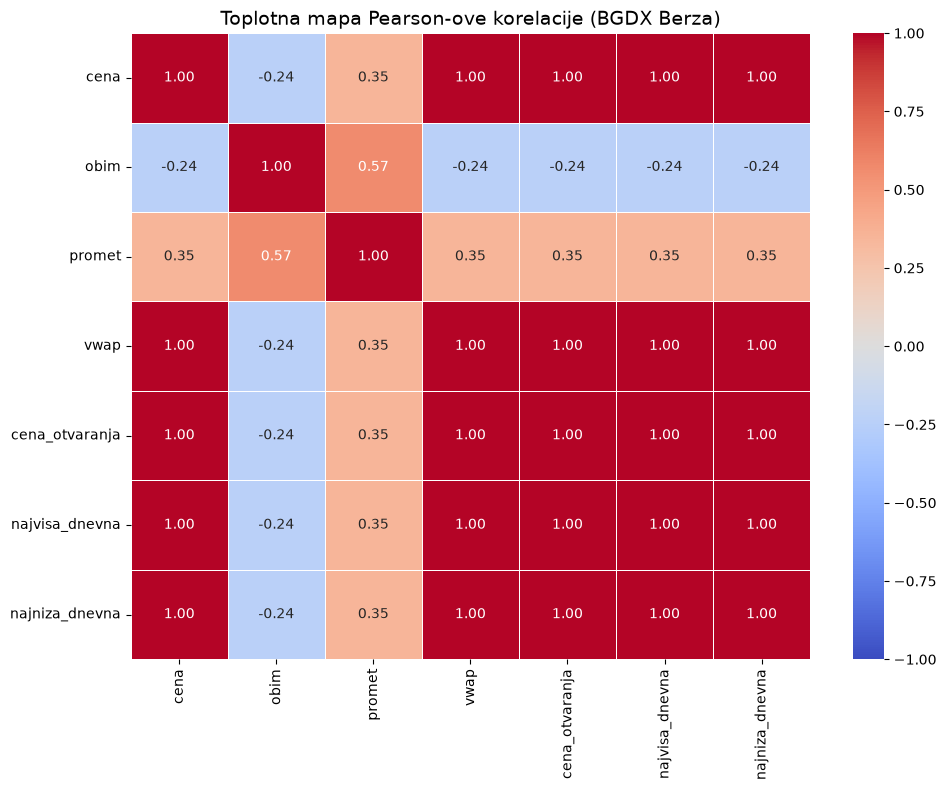

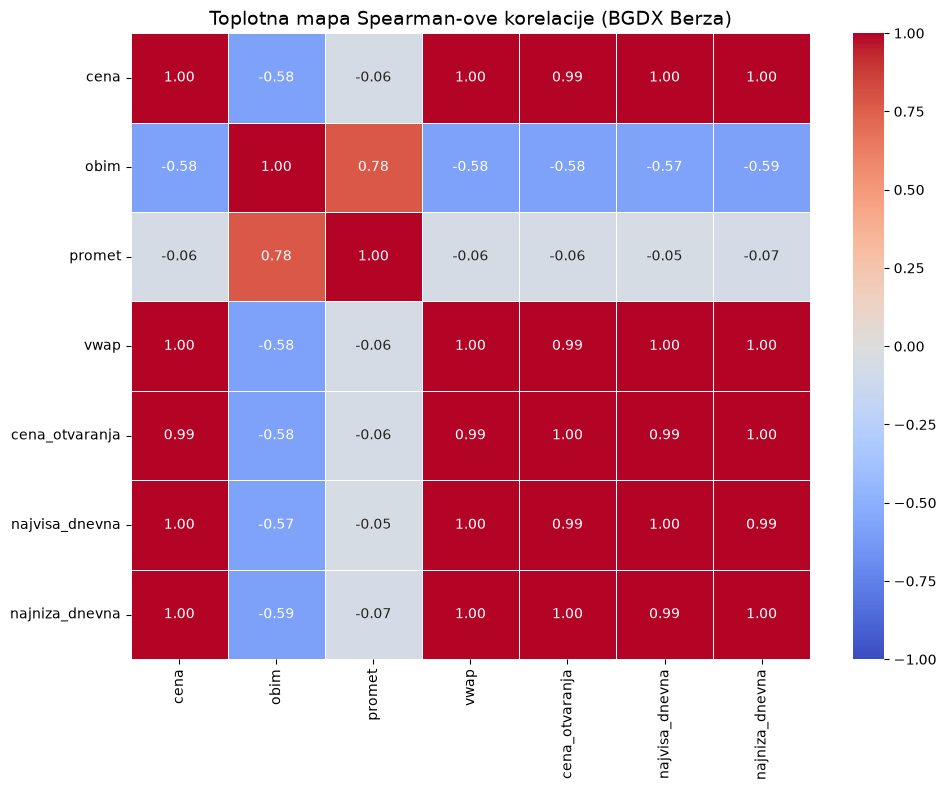

In [2]:
import pandas as pd
import seaborn as sbn
import matplotlib.pyplot as plt

# 1. Učitavanje izvornog skupa podataka iz baze
query = """
SELECT ticker, vreme, cena, obim, promet, vwap, cena_otvaranja, najvisa_dnevna, najniza_dnevna 
FROM istorija_cena;
"""
df = pd.read_sql(query, con=engine)
print(f"Ukupno učitano redova: {df.shape[0]}")

# 2. Filtriranje i čišćenje niske likvidnosti (uklanjanje nultih obima)
df_validno = df[(df['obim'] > 0) & (df['obim'].notna())]
print(f"Broj redova nakon uklanjanja nultih obima: {df_validno.shape[0]}")

# 3. Statistička analiza korelacije (Pearson i Spearman)
numericke_kolone = ['cena', 'obim', 'promet', 'vwap', 'cena_otvaranja', 'najvisa_dnevna', 'najniza_dnevna']

pearson_corr = df_validno[numericke_kolone].corr(method='pearson')
spearman_corr = df_validno[numericke_kolone].corr(method='spearman')

print("\n--- Pearsonova korelaciona matrica ---")
display(pearson_corr)

print("\n--- Spearman-ova korelaciona matrica ---")
display(spearman_corr)

# 4. Vizuelizacija multikolinearnosti Pearson (Toplotna mapa / Heatmap)
plt.figure(figsize=(10, 8))
sbn.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Toplotna mapa Pearson-ove korelacije (BGDX Berza)", fontsize=14)
plt.tight_layout()
plt.show()

# 5. Vizuelizacija multikolinearnosti Spearman (Toplotna mapa / Heatmap)
plt.figure(figsize=(10, 8))
sbn.heatmap(spearman_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Toplotna mapa Spearman-ove korelacije (BGDX Berza)", fontsize=14)
plt.tight_layout()
plt.show()

### 3. Dijagrami rasipanja (*Scatter Plots*) i kvantifikacija multikolinearnosti (VIF)

- **Vizuelna analiza odnosa putem dijagrama rasipanja:** U skladu sa ciljevima rada, generisani su dijagrami rasipanja za karakteristične parove atributa kako bi se vizuelno potvrdila priroda njihove međusobne zavisnosti. Poseban fokus stavljen je na odnos visoko korelisanih cenovnih obeležja (`cena` u odnosu na `vwap`), gde se očekuje gotovo idealno linearno poklapanje tačaka duž dijagonale, kao i na odnos likvidnosti i vrednosti (`cena` u odnosu na `obim`), gde Spearmanova korelacija ukazuje na nelinearnu distribuciju i prisustvo ekstremnih vrednosti (*outliers*).
- **Izračunavanje faktora inflacije varijanse (VIF):** Radi formalne i numeričke potvrde multikolinearnosti među svim ulaznim prediktorima istovremeno (izvan bivarijantne analize parova), primenjen je VIF test. Vrednosti $\text{VIF} \ge 10$ služe kao objektivan kriterijum za identifikaciju redundantnih atributa koje je potrebno izostaviti u eksperimentalnoj fazi modeliranja.

In [ ]:
import pandas as pd
import seaborn as sbn
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Dijagrami rasipanja (Scatter Plots) za karakteristične parove atributa
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Levi grafik: Ekstremna multikolinearnost (cena vs vwap)
sbn.scatterplot(data=df_validno, x='vwap', y='cena', alpha=0.5, ax=axes[0], color='crimson')
axes[0].set_title("Dijagram rasipanja: Cena vs VWAP (Linearna zavisnost)", fontsize=12)
axes[0].set_xlabel("VWAP (RSD)")
axes[0].set_ylabel("Cena zatvaranja (RSD)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Desni grafik: Nelinearna veza i ekstremi (obim vs cena)
sbn.scatterplot(data=df_validno, x='obim', y='cena', alpha=0.5, ax=axes[1], color='steelblue')
axes[1].set_title("Dijagram rasipanja: Obim vs Cena (Nelinearnost i ekstremi)", fontsize=12)
axes[1].set_xlabel("Obim trgovanja (broj akcija)")
axes[1].set_ylabel("Cena zatvaranja (RSD)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Izračunavanje Faktora inflacije varijanse (VIF) preko R^2 linearne regresije
prediktori = ['obim', 'promet', 'vwap', 'cena_otvaranja', 'najvisa_dnevna', 'najniza_dnevna']
X_vif = df_validno[prediktori].dropna()

vif_rezultati = []
for i, kolona in enumerate(prediktori):
    ostale_kolone = [c for j, c in enumerate(prediktori) if j != i]
    X_ostali = X_vif[ostale_kolone]
    y_tekuci = X_vif[kolona]
    
    model_vif = LinearRegression().fit(X_ostali, y_tekuci)
    r2 = model_vif.score(X_ostali, y_tekuci)
    
    # Zaštita od deljenja nulom ako je R^2 == 1.0
    vif_val = float('inf') if (1.0 - r2) <= 1e-12 else 1.0 / (1.0 - r2)
    vif_rezultati.append({"Atribut": kolona, "R2": round(r2, 6), "VIF": round(vif_val, 2)})

vif_podaci = pd.DataFrame(vif_rezultati).sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("--- Faktor inflacije varijanse (VIF) za ulazne atribute ---")
display(vif_podaci)

ModuleNotFoundError: No module named 'statsmodels'